# QF620 Project — Part D: Realized volatility

**Goal:** measure how much the S&P 500 futures (ES) actually moved each day from Apr 1 to Apr 10, 2025, and compare that with what options were pricing (VIX and Part B's at-the-money implied vol).

Files needed in the same folder as this notebook (the same files the rest of the team uses):
- `RTH.zip` (regular-hours data, 09:30–16:15)
- `ETH.zip` (overnight data, 20:15 → 09:15 the next morning)

We only use the `*_assets.csv` files inside them (columns: SPX, ES_BID, ES_ASK, VIX). All times are New York time.

Two inputs come from teammates and are typed in where they are used:
- **Part A:** verified headline times (Part A notebook, Step 6)
- **Part B:** at-the-money implied vols (Part B notebook, summary table)

In [1]:
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The eight trading days in the data
DAYS = ["2025-04-01", "2025-04-02", "2025-04-03", "2025-04-04",
        "2025-04-07", "2025-04-08", "2025-04-09", "2025-04-10"]

# Numbers used to annualize (from the team plan)
INTERVALS_PER_DAY = 78    # 5-minute intervals in a 09:30-16:00 trading day
TRADING_DAYS = 252        # trading days in a year

## Step 0. Load the data and check it

This small function opens a zip file and reads one day's `assets` file straight from it, so nothing needs to be unzipped.

In [3]:
def read_assets(zip_name, date):
    with zipfile.ZipFile(zip_name) as z:
        # find the file inside the zip whose name ends with e.g. "2025-04-01_assets.csv"
        name = [n for n in z.namelist() if n.endswith(f"{date}_assets.csv")][0]
        with z.open(name) as f:
            df = pd.read_csv(f, index_col = 0, parse_dates = True)
    return df

In [4]:
frames = []

for d in DAYS:
    df = read_assets("RTH.zip", d)
    df["day"] = d
    frames.append(df)

rth = pd.concat(frames)

# Futures mid price
rth["es_mid"] = (rth["ES_BID"] + rth["ES_ASK"]) / 2

rth.head()

,SPX,ES_BID,ES_ASK,VIX,day,es_mid
2025-04-01 09:31:21.491248,5590.32,5631.75,5632.00,22.66,2025-04-01,5631.875
2025-04-01 09:31:24.535800,5590.70,5631.75,5632.00,22.66,2025-04-01,5631.875
2025-04-01 09:31:27.582698,5589.06,5629.50,5629.75,22.66,2025-04-01,5629.625
2025-04-01 09:31:30.632772,5588.66,5630.50,5630.75,22.66,2025-04-01,5630.625
2025-04-01 09:31:33.638817,5588.82,5629.75,5630.00,22.69,2025-04-01,5629.875


**Check the rows before using them.** How far apart are the quotes, and are there holes?

In [5]:
check = []

for d, x in rth.groupby("day"):
    seconds_between = x.index.to_series().diff().dt.total_seconds()
    check.append({"day": d,
                  "rows": len(x),
                  "first_quote": x.index[0].strftime("%H:%M:%S"),
                  "last_quote": x.index[-1].strftime("%H:%M:%S"),
                  "median_seconds_between": seconds_between.median(),
                  "longest_gap_seconds": seconds_between.max()})

pd.DataFrame(check).set_index("day").round(1)

,rows,first_quote,last_quote,median_seconds_between,longest_gap_seconds
day,,,,,
2025-04-01,7980,09:31:21,16:14:59,3.0,18.3
2025-04-02,7974,09:31:21,16:14:58,3.0,15.2
2025-04-03,7985,09:31:21,16:14:58,3.0,9.1
2025-04-04,8000,09:31:22,16:14:58,3.0,6.1
2025-04-07,7856,09:31:22,16:14:58,3.0,39.5
2025-04-08,7979,09:31:21,16:14:58,3.0,9.1
2025-04-09,7906,09:31:21,16:14:59,3.0,51.6
2025-04-10,7476,09:57:17,16:14:58,3.0,63.6


What this tells us:
- Quotes come about every **3.04 seconds**, so 100 rows ≈ 5 minutes, as the plan says.
- But some days have **gaps of up to ~64 seconds**, so "every 100th row" would slowly drift away from real 5-minute marks.
- Files start at **09:31** (Apr 10 at **09:57**) and run to **16:15**, 15 minutes after the stock market closes.

**Our choice:** take the last quote in each 5-minute *clock* slot (09:35, 09:40, …, 16:00) instead of every 100th row, and cut each day at 16:00. This gives 77 returns a day (72 on Apr 10), matching the 78 intervals used to annualize.

## Step 1. Futures mid every 5 minutes

In [6]:
def five_min_mids(x):
    regular_hours = x.between_time("09:30", "16:00")
    # slot ending 09:35 = last quote from 09:30:00 up to (not including) 09:35:00
    return (regular_hours["es_mid"]
            .resample("5min", label = "right", closed = "left")
            .last()
            .dropna())

bars = {d: five_min_mids(x) for d, x in rth.groupby("day")}

bars["2025-04-01"].head()

2025-04-01 09:35:00    5633.125
2025-04-01 09:40:00    5634.875
2025-04-01 09:45:00    5633.375
2025-04-01 09:50:00    5647.875
2025-04-01 09:55:00    5645.625
Freq: 5min, Name: es_mid, dtype: float64

## Step 2. Log returns, realized variance and annualized volatility

- Log return: r = ln(P_t / P_t−1), only within a day
- Realized variance: RV = sum of r²
- Annualized vol = √(RV / n × 78 × 252), where n is the number of returns that day

In [7]:
returns = {d: np.log(bars[d]).diff().dropna() for d in DAYS}

daily = pd.DataFrame(index = DAYS)
daily.index.name = "day"

daily["n_returns"] = [len(returns[d]) for d in DAYS]
daily["RV"] = [(returns[d] ** 2).sum() for d in DAYS]
daily["realized_vol_%"] = np.sqrt(daily["RV"] / daily["n_returns"] * INTERVALS_PER_DAY * TRADING_DAYS) * 100

daily.round(6)

,n_returns,RV,realized_vol_%
day,,,
2025-04-01,77,0.000093,15.439889
2025-04-02,77,0.000108,16.584046
2025-04-03,77,0.000120,17.467046
2025-04-04,77,0.000807,45.391803
2025-04-07,77,0.004069,101.912333
2025-04-08,77,0.000844,46.405816
2025-04-09,77,0.002075,72.783341
2025-04-10,72,0.001098,54.761632


In [8]:
# The whole shock window, Apr 3-10, pooled together (regular hours only)
window = pd.concat([returns[d] for d in DAYS[2:]])

rv_window = np.sqrt((window ** 2).sum() / len(window) * INTERVALS_PER_DAY * TRADING_DAYS) * 100

print(f"Realized vol, Apr 3-10, regular hours: {rv_window:.1f}%")

Realized vol, Apr 3-10, regular hours: 62.3%


## Step 3. Bipower variation and jump share

- Bipower variation: BV = π/2 × Σ |r_t| · |r_t−1|. Multiplying each return by its neighbour means one big isolated jump stays small, so BV measures the smooth part of the movement.
- Jump share = (RV − BV) / RV. A small negative value is just noise, so we report it as 0.

In [9]:
def bipower(r):
    return np.pi / 2 * (r.abs() * r.abs().shift(1)).sum()

daily["BV"] = [bipower(returns[d]) for d in DAYS]
daily["bipower_vol_%"] = np.sqrt(daily["BV"] / daily["n_returns"] * INTERVALS_PER_DAY * TRADING_DAYS) * 100
daily["jump_share_raw"] = (daily["RV"] - daily["BV"]) / daily["RV"]
daily["jump_share"] = daily["jump_share_raw"].clip(lower = 0)

daily[["realized_vol_%", "bipower_vol_%", "jump_share_raw", "jump_share"]].round(2)

,realized_vol_%,bipower_vol_%,jump_share_raw,jump_share
day,,,,
2025-04-01,15.44,15.59,-0.02,0.00
2025-04-02,16.58,16.47,0.01,0.01
2025-04-03,17.47,16.30,0.13,0.13
2025-04-04,45.39,45.16,0.01,0.01
2025-04-07,101.91,69.81,0.53,0.53
2025-04-08,46.41,44.32,0.09,0.09
2025-04-09,72.78,67.07,0.15,0.15
2025-04-10,54.76,54.94,-0.01,0.00


## Step 4. Largest 5-minute move each day, compared with Part A's verified times

In [10]:
for d in DAYS:
    r = returns[d]
    t = r.abs().idxmax()                       # slot with the biggest move (up or down)
    daily.loc[d, "largest_move_%"] = r[t] * 100
    daily.loc[d, "largest_move_slot"] = (t - pd.Timedelta("5min")).strftime("%H:%M") + "-" + t.strftime("%H:%M")

daily[["largest_move_%", "largest_move_slot"]].round(2)

,largest_move_%,largest_move_slot
day,,
2025-04-01,-0.26,10:00-10:05
2025-04-02,-0.31,14:55-15:00
2025-04-03,-0.34,10:00-10:05
2025-04-04,-0.98,11:25-11:30
2025-04-07,3.76,10:10-10:15
2025-04-08,1.36,15:50-15:55
2025-04-09,2.18,13:20-13:25
2025-04-10,1.04,12:30-12:35


**Part A's verified times** (Part A notebook, Step 6) for the headlines that fell in regular hours and moved the market.
For each one we look up our 5-minute return in the slot containing that time, the next slot, and how the slot ranks within its day (1 = biggest move).

In [11]:
part_a = pd.DataFrame(
    [["2025-04-07 10:10", "False 90-day pause report"],
     ["2025-04-07 10:34", "White House denial (CNBC 10:33)"],
     ["2025-04-07 11:15", "Trump 50% ultimatum to China"],
     ["2025-04-09 13:18", "Real 90-day pause"]],
    columns = ["verified_time", "headline"])

rows = []

for _, e in part_a.iterrows():
    t = pd.Timestamp(e["verified_time"])
    r = returns[t.strftime("%Y-%m-%d")]
    slot_end = t.floor("5min") + pd.Timedelta("5min")
    move = r[slot_end]
    rows.append({"headline": e["headline"],
                 "verified_time": t.strftime("%H:%M"),
                 "slot": (slot_end - pd.Timedelta("5min")).strftime("%H:%M") + "-" + slot_end.strftime("%H:%M"),
                 "move_%": move * 100,
                 "next_slot_move_%": r[slot_end + pd.Timedelta("5min")] * 100,
                 "rank_in_day": (r.abs() > abs(move)).sum() + 1,
                 "returns_that_day": len(r)})

pd.DataFrame(rows).set_index("headline").round(2)

,verified_time,slot,move_%,next_slot_move_%,rank_in_day,returns_that_day
headline,,,,,,
False 90-day pause report,10:10,10:10-10:15,3.76,0.21,1,77
White House denial (CNBC 10:33),10:34,10:30-10:35,0.25,-1.15,41,77
Trump 50% ultimatum to China,11:15,11:15-11:20,-0.76,-0.88,14,77
Real 90-day pause,13:18,13:15-13:20,2.01,2.18,2,77


What this shows:
- **Apr 7, 10:10 (fake pause):** our biggest move of the day (+3.76%) is in exactly that slot. ✓
- **Apr 9, 13:18 (real pause):** the slots on either side of 13:18 are the day's two biggest moves. ✓
- **Apr 7 denial (10:34):** the −2.94% drop at 10:20–10:25 came *before* the denial: the rally peaked at 10:17 and the market started doubting the report on its own. The denial then brought a second leg (−1.15% at 10:35–10:40).
- **Apr 4:** the biggest move (−0.98% at 11:25–11:30) is not one of Part A's headlines. It lines up with Powell's speech at about 11:25 (PBS NewsHour live coverage).
- Apr 1, 2, 3, 8 and 10: no verified regular-hours headline; the largest moves are small.

## Step 5. Overnight gaps (kept separate from realized variance)

Overnight gap = ln(first mid today / last mid at or before 16:00 on the previous trading day).

In [12]:
first_mid = rth.groupby("day")["es_mid"].first()
close_mid = rth.between_time("09:30", "16:00").groupby("day")["es_mid"].last()

daily["overnight_gap_%"] = np.log(first_mid / close_mid.shift(1)) * 100
daily["rth_return_%"] = np.log(close_mid / first_mid) * 100
daily["close_to_close_%"] = np.log(close_mid / close_mid.shift(1)) * 100

daily[["overnight_gap_%", "rth_return_%", "close_to_close_%"]].round(2)

,overnight_gap_%,rth_return_%,close_to_close_%
day,,,
2025-04-01,NaN,0.77,NaN
2025-04-02,-1.08,1.72,0.64
2025-04-03,-3.31,-1.65,-4.95
2025-04-04,-2.34,-3.82,-6.16
2025-04-07,-3.68,3.38,-0.30
2025-04-08,3.22,-4.74,-1.52
2025-04-09,-0.46,9.34,8.88
2025-04-10,-2.34,-1.06,-3.40


In [13]:
total_gaps = daily["overnight_gap_%"].sum()
total_rth = daily["rth_return_%"].iloc[1:].sum()          # Apr 2-10, same span as the gaps
total_cc = daily["close_to_close_%"].sum()

print(f"Overnight gaps, Apr 2-10:          {total_gaps:+.2f}%")
print(f"Regular-hours moves, Apr 2-10:     {total_rth:+.2f}%")
print(f"Apr 1 close to Apr 10 close:       {total_cc:+.2f}%")
print(f"Check (gaps + regular hours - total, should be 0): {total_gaps + total_rth - total_cc:.10f}")

# Close-to-close annualized vol over Apr 3-10 (6 daily returns), including the gaps
cc = daily.loc["2025-04-03":, "close_to_close_%"] / 100
cc_vol = np.sqrt((cc ** 2).mean() * TRADING_DAYS) * 100
print(f"\nClose-to-close vol, Apr 3-10: {cc_vol:.1f}%   vs regular hours only: {rv_window:.1f}%")

Overnight gaps, Apr 2-10:          -9.98%
Regular-hours moves, Apr 2-10:     +3.16%
Apr 1 close to Apr 10 close:       -6.82%
Check (gaps + regular hours - total, should be 0): 0.0000000000

Close-to-close vol, Apr 3-10: 80.8%   vs regular hours only: 62.3%


**Where did the overnight moves happen?** The ETH file for a date covers that evening (20:15) to 09:15 the next morning, so the night *before* each RTH day is in the previous date's ETH file (Sunday night for Monday Apr 7). We find the lowest overnight mid, measured against the previous 16:00 close.

In [14]:
night_before = {"2025-04-02": "2025-04-01", "2025-04-03": "2025-04-02", "2025-04-04": "2025-04-03",
                "2025-04-07": "2025-04-06", "2025-04-08": "2025-04-07", "2025-04-09": "2025-04-08",
                "2025-04-10": "2025-04-09"}

rows = []

for d, night in night_before.items():
    eth = read_assets("ETH.zip", night)
    previous_close = close_mid.iloc[DAYS.index(d) - 1]

    if len(eth) == 0:
        rows.append({"day": d, "eth_file": night, "overnight_low_%": np.nan, "time_of_low": "ETH file empty"})
        continue

    mid = (eth["ES_BID"] + eth["ES_ASK"]) / 2
    rows.append({"day": d,
                 "eth_file": night,
                 "overnight_low_%": np.log(mid.min() / previous_close) * 100,
                 "time_of_low": mid.idxmin().strftime("%a %H:%M")})

pd.DataFrame(rows).set_index("day").round(2)

,eth_file,overnight_low_%,time_of_low
day,,,
2025-04-02,2025-04-01,-1.11,Wed 08:29
2025-04-03,2025-04-02,-3.93,Thu 09:02
2025-04-04,2025-04-03,-4.18,Fri 07:30
2025-04-07,2025-04-06,-5.39,Mon 03:04
2025-04-08,2025-04-07,0.62,Mon 21:01
2025-04-09,2025-04-08,-2.91,Wed 01:39
2025-04-10,2025-04-09,NaN,ETH file empty


## Step 6. VIX path: open, high, low, close, and how fast it fell back

In [15]:
regular = rth.between_time("09:30", "16:00")

vix = regular.groupby("day")["VIX"].agg(["first", "max", "min", "last"])
vix.columns = ["VIX_open", "VIX_high", "VIX_low", "VIX_close"]
vix["time_of_high"] = regular.groupby("day")["VIX"].idxmax().dt.strftime("%H:%M")

vix

,VIX_open,VIX_high,VIX_low,VIX_close,time_of_high
day,,,,,
2025-04-01,22.66,23.52,21.58,21.83,10:21
2025-04-02,23.51,23.51,20.68,21.45,09:31
2025-04-03,26.44,29.71,26.15,29.71,15:59
2025-04-04,36.57,45.22,35.81,43.85,14:46
2025-04-07,50.63,54.20,38.58,48.26,11:15
2025-04-08,38.80,57.52,36.48,52.67,15:50
2025-04-09,52.66,52.66,31.90,33.41,09:31
2025-04-10,36.29,54.87,36.29,41.18,12:28


**How fast VIX fell back.** We measure the time VIX took to give back **half** of its rise from the Apr 2 close (before the announcement) to its highest close (Apr 8).

In [16]:
pre_event = vix.loc["2025-04-02", "VIX_close"]
peak = vix.loc["2025-04-08", "VIX_close"]
halfway = (pre_event + peak) / 2

vix_apr9 = rth.loc[rth["day"] == "2025-04-09", "VIX"]
first_below = vix_apr9[vix_apr9 <= halfway].index[0]
pause_time = pd.Timestamp("2025-04-09 13:18")       # Part A verified time

print(f"VIX: Apr 2 close {pre_event:.2f} -> Apr 8 close {peak:.2f} (rise of {peak - pre_event:.2f} points)")
print(f"Half-way level: {halfway:.2f}")
print(f"First at or below half-way: {first_below:%H:%M:%S} on Apr 9, "
      f"{(first_below - pause_time).total_seconds() / 60:.1f} minutes after the 13:18 pause")
print(f"Share of the rise given back by the Apr 9 close: {(peak - vix.loc['2025-04-09', 'VIX_close']) / (peak - pre_event):.0%}")
print(f"Apr 10 close: {vix.loc['2025-04-10', 'VIX_close']:.2f}")

VIX: Apr 2 close 21.45 -> Apr 8 close 52.67 (rise of 31.22 points)
Half-way level: 37.06
First at or below half-way: 13:28:19 on Apr 9, 10.3 minutes after the 13:18 pause
Share of the rise given back by the Apr 9 close: 62%
Apr 10 close: 41.18


**Fake vs real pause.** Same convention as Part A (Step 9): start from Part A's verified time t, and measure changes from the 1-minute bar 5 minutes before (the last quote before t − 4 minutes). ES moves are simple % changes, as in Part A.

In [17]:
def last_before(day_data, t):
    return day_data.loc[: t - pd.Timedelta("1ns")].iloc[-1]

def pause_numbers(verified_time):
    t = pd.Timestamp(verified_time)
    day_data = rth[rth["day"] == t.strftime("%Y-%m-%d")]

    before = last_before(day_data, t - pd.Timedelta("4min"))     # 1-minute bar at t - 5
    after10 = last_before(day_data, t + pd.Timedelta("11min"))   # 1-minute bar at t + 10
    after60 = last_before(day_data, t + pd.Timedelta("61min"))   # 1-minute bar at t + 60

    hour = day_data.loc[t : t + pd.Timedelta("60min")]
    low_time = hour["VIX"].idxmin()
    later = day_data.loc[low_time:]
    back = later[later["VIX"] >= before["VIX"]]

    return {"VIX_-5min": before["VIX"],
            "ES_move_+10min_%": (after10["es_mid"] / before["es_mid"] - 1) * 100,
            "largest_VIX_fall": hour["VIX"].min() - before["VIX"],
            "time_of_VIX_low": low_time.strftime("%H:%M"),
            "VIX_back_above_at": back.index[0].strftime("%H:%M") if len(back) > 0 else "not that day",
            "VIX_+60min": after60["VIX"],
            "VIX_change_+60min": after60["VIX"] - before["VIX"],
            "ES_move_+60min_%": (after60["es_mid"] / before["es_mid"] - 1) * 100}

pause_table = pd.DataFrame({"Fake pause, Apr 7 10:10": pause_numbers("2025-04-07 10:10"),
                            "Real pause, Apr 9 13:18": pause_numbers("2025-04-09 13:18")})

pause_table

,"Fake pause, Apr 7 10:10","Real pause, Apr 9 13:18"
VIX_-5min,48.18,48.01
ES_move_+10min_%,2.852295,4.687808
largest_VIX_fall,-9.6,-13.47
time_of_VIX_low,10:17,13:36
VIX_back_above_at,10:24,not that day
VIX_+60min,46.41,36.85
VIX_change_+60min,-1.77,-11.16
ES_move_+60min_%,1.48479,7.040343


The ES moves match Part A's table exactly (fake +2.85% / +1.48%, real +4.69% / +7.04%).
After the fake report, VIX was back above its earlier level by 10:24. After the real pause, most of the VIX drop was still there an hour later.

## Present: the daily table

In [18]:
# Part B's at-the-money implied vol (Part B notebook, summary table).
# About 15:55 each day, except Apr 3 at 10:00. Part B has no value for Apr 2, 7 and 10.
part_b_atm = pd.Series({"2025-04-01": 20.30, "2025-04-03": 25.43, "2025-04-04": 45.47,
                        "2025-04-08": 41.08, "2025-04-09": 25.39})

daily_table = pd.DataFrame({
    "realized_vol_%": daily["realized_vol_%"],
    "jump_share": daily["jump_share"],
    "largest_5min_move_%": daily["largest_move_%"],
    "largest_move_slot": daily["largest_move_slot"],
    "overnight_gap_%": daily["overnight_gap_%"],
    "VIX_close": vix["VIX_close"],
    "PartB_ATM_vol_%": part_b_atm})

daily_table.round(2)

,realized_vol_%,jump_share,largest_5min_move_%,largest_move_slot,overnight_gap_%,VIX_close,PartB_ATM_vol_%
2025-04-01,15.44,0.00,-0.26,10:00-10:05,NaN,21.83,20.30
2025-04-02,16.58,0.01,-0.31,14:55-15:00,-1.08,21.45,NaN
2025-04-03,17.47,0.13,-0.34,10:00-10:05,-3.31,29.71,25.43
2025-04-04,45.39,0.01,-0.98,11:25-11:30,-2.34,43.85,45.47
2025-04-07,101.91,0.53,3.76,10:10-10:15,-3.68,48.26,NaN
2025-04-08,46.41,0.09,1.36,15:50-15:55,3.22,52.67,41.08
2025-04-09,72.78,0.15,2.18,13:20-13:25,-0.46,33.41,25.39
2025-04-10,54.76,0.00,1.04,12:30-12:35,-2.34,41.18,NaN


## Present: Figure 1 — realized vol against VIX and Part B's at-the-money vol

All three are annualized volatility in %, so they share one axis.

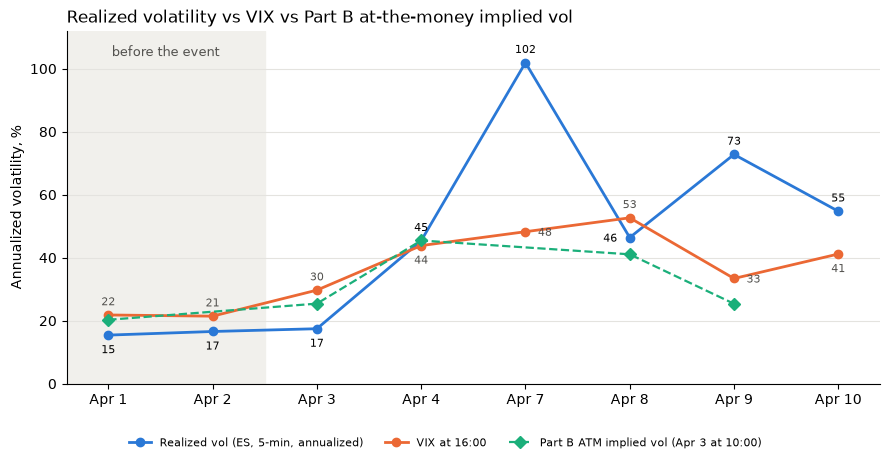

In [19]:
labels = ["Apr 1", "Apr 2", "Apr 3", "Apr 4", "Apr 7", "Apr 8", "Apr 9", "Apr 10"]
x = np.arange(len(DAYS))

rv = daily_table["realized_vol_%"].values
vx = daily_table["VIX_close"].values
b_x = [DAYS.index(d) for d in part_b_atm.index]

fig, ax = plt.subplots(figsize = (9, 4.6))

ax.axvspan(-0.4, 1.5, color = "#f1f0ec", zorder = 0)
ax.text(0.55, 104, "before the event", ha = "center", fontsize = 9, color = "#52514e")

ax.plot(x, rv, "-o", color = "#2a78d6", lw = 2, ms = 6, label = "Realized vol (ES, 5-min, annualized)")
ax.plot(x, vx, "-o", color = "#eb6834", lw = 2, ms = 6, label = "VIX at 16:00")
ax.plot(b_x, part_b_atm.values, "--D", color = "#1baf7a", lw = 1.6, ms = 6,
        label = "Part B ATM implied vol (Apr 3 at 10:00)")

for i in range(len(DAYS)):
    ax.annotate(f"{rv[i]:.0f}", (i, rv[i]), textcoords = "offset points",
                xytext = (-9, -3) if i == 5 else (0, 7 if rv[i] >= vx[i] else -13),
                ha = "right" if i == 5 else "center", fontsize = 8)
    ax.annotate(f"{vx[i]:.0f}", (i, vx[i]), textcoords = "offset points",
                xytext = (9, -3) if i in (4, 6) else (0, 7 if vx[i] > rv[i] else -13),
                ha = "left" if i in (4, 6) else "center", fontsize = 8, color = "#52514e")

ax.set_xticks(x, labels)
ax.set_ylabel("Annualized volatility, %")
ax.set_ylim(0, 112)
ax.set_xlim(-0.4, 7.4)
ax.grid(axis = "y", color = "#e4e3df")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Realized volatility vs VIX vs Part B at-the-money implied vol", loc = "left")
fig.legend(loc = "lower center", ncol = 3, fontsize = 8, frameon = False)
fig.tight_layout(rect = (0, 0.07, 1, 1))

fig.savefig("PartD_Figure1_RealizedVol_vs_VIX_vs_ATM.png", dpi = 200)
plt.show()

## Extra: Figure 2 — overnight gap vs regular-hours move

Not required by the plan, but it shows something no other part covers: the whole net fall happened overnight.

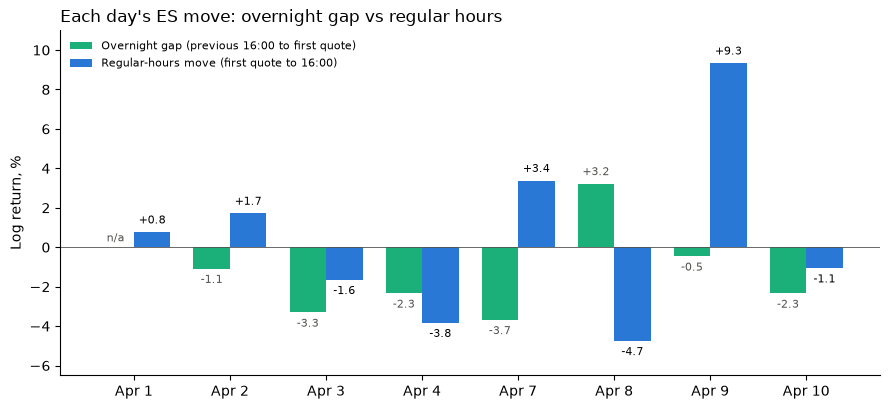

In [20]:
gap = daily["overnight_gap_%"].fillna(0).values
rth_move = daily["rth_return_%"].values
w = 0.38

fig, ax = plt.subplots(figsize = (9, 4.2))

ax.bar(x - w / 2, gap, w, color = "#1baf7a", label = "Overnight gap (previous 16:00 to first quote)")
ax.bar(x + w / 2, rth_move, w, color = "#2a78d6", label = "Regular-hours move (first quote to 16:00)")

for i in range(len(DAYS)):
    if i > 0:
        ax.text(i - w / 2, gap[i] + (0.3 if gap[i] >= 0 else -0.3), f"{gap[i]:+.1f}",
                ha = "center", va = "bottom" if gap[i] >= 0 else "top", fontsize = 8, color = "#52514e")
    ax.text(i + w / 2, rth_move[i] + (0.3 if rth_move[i] >= 0 else -0.3), f"{rth_move[i]:+.1f}",
            ha = "center", va = "bottom" if rth_move[i] >= 0 else "top", fontsize = 8)
ax.text(-w / 2, 0.3, "n/a", ha = "center", fontsize = 8, color = "#52514e")

ax.axhline(0, color = "#52514e", lw = 0.6)
ax.set_xticks(x, labels)
ax.set_ylabel("Log return, %")
ax.set_ylim(-6.5, 11)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Each day's ES move: overnight gap vs regular hours", loc = "left")
ax.legend(loc = "upper left", fontsize = 8, frameon = False)
fig.tight_layout()

fig.savefig("PartD_Figure2_Overnight_gap_vs_regular_hours.png", dpi = 200)
plt.show()

## Key numbers for the write-up

In [21]:
print(f"Realized vol before the event (Apr 1-2): {daily.loc['2025-04-01', 'realized_vol_%']:.1f}% and {daily.loc['2025-04-02', 'realized_vol_%']:.1f}%")
print(f"Realized vol peak: {daily['realized_vol_%'].max():.1f}% on {daily['realized_vol_%'].idxmax()}")
print(f"Realized vol Apr 3-10: {rv_window:.1f}% regular hours, {cc_vol:.1f}% close-to-close")
print(f"VIX on Apr 2: {pre_event:.2f}")
print(f"Highest jump share: {daily['jump_share'].max():.2f} on {daily['jump_share'].idxmax()}")
print(f"Overnight gaps total: {total_gaps:+.1f}%, regular hours total: {total_rth:+.1f}%")

Realized vol before the event (Apr 1-2): 15.4% and 16.6%
Realized vol peak: 101.9% on 2025-04-07
Realized vol Apr 3-10: 62.3% regular hours, 80.8% close-to-close
VIX on Apr 2: 21.45
Highest jump share: 0.53 on 2025-04-07
Overnight gaps total: -10.0%, regular hours total: +3.2%
